In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

In [51]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
columns = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigree",
    "Age",
    "Outcome"
]
df = pd.read_csv(url, names=columns)
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [40]:
columns_with_zero = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]
for column in columns_with_zero:
    df[column] = df[column].replace(0, np.nan)
    df[column] = df[column].fillna(df[column].median())
print(df.isnull().sum())

Pregnancies         0
Glucose             0
BloodPressure       0
SkinThickness       0
Insulin             0
BMI                 0
DiabetesPedigree    0
Age                 0
Outcome             0
dtype: int64


In [41]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (614, 8)
Testing data: (154, 8)


In [43]:
svm_model = SVC()
svm_model.fit(X_train_scaled, y_train)
svm_prediction = svm_model.predict(X_test_scaled)
svm_accuracy = accuracy_score(y_test, svm_prediction)

print("SVM Accuracy:", svm_accuracy)

SVM Accuracy: 0.7467532467532467


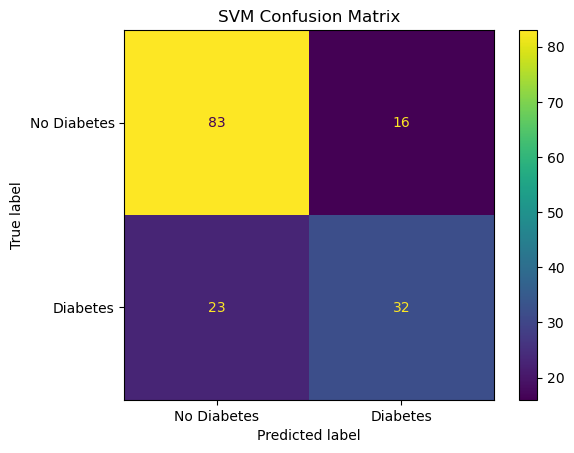

In [44]:
cm = confusion_matrix(y_test, svm_prediction)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Diabetes', "Diabetes"])
display.plot()
plt.title("SVM Confusion Matrix")
plt.show()

In [48]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_scaled, y_train)
dt_prediction = dt_model.predict(X_test_scaled)
dt_accuracy = accuracy_score(y_test, dt_prediction)
print("Decision Tree Accuracy:",dt_accuracy)

Decision Tree Accuracy: 0.7142857142857143


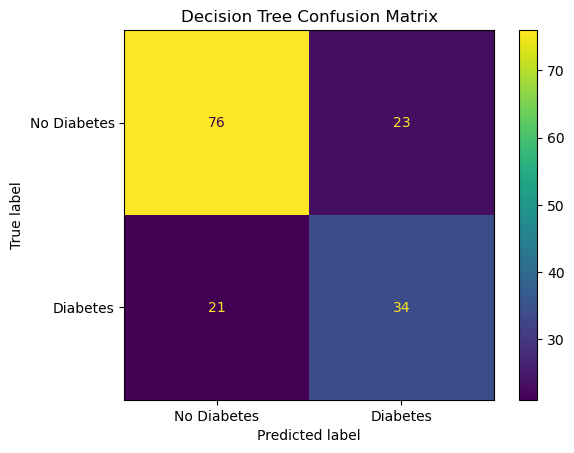

In [49]:
cm = confusion_matrix(y_test, dt_prediction)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Diabetes", "Diabetes"])
display.plot()
plt.title("Decision Tree Confusion Matrix")
plt.show()

In [50]:
print("SVM Accuracy:", svm_accuracy)
print("Decision Tree Accuracy:", dt_accuracy)

if svm_accuracy > dt_accuracy:
    print("SVM performed better")
elif dt_accuracy > svm_accuracy:
    print("Decision Tree performed better")
else:
    print("Both models have the same accuracy.")

SVM Accuracy: 0.7467532467532467
Decision Tree Accuracy: 0.7142857142857143
SVM performed better
